<a href="https://colab.research.google.com/github/elisalsr/advertising-response-curves/blob/main/advertising_response_curves.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advertising response curves and budget allocation

## 1. Data exploration

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/facebookexperimental/Robyn/main/python/src/robyn/tutorials/resources/dt_simulated_weekly.csv"
df = pd.read_csv(url, parse_dates=["DATE"])

print(df.shape)
df.head()

(208, 12)


,DATE,revenue,tv_S,ooh_S,print_S,facebook_I,search_clicks_P,search_S,competitor_sales_B,facebook_S,events,newsletter
0,2015-11-23,2.754372e+06,22358.346667,0.0,12728.488889,2.430128e+07,0.000000,0.000000,8125009,7607.132915,na,19401.653846
1,2015-11-30,2.584277e+06,28613.453333,0.0,0.000000,5.527033e+06,9837.238486,4133.333333,7901549,1141.952450,na,14791.000000
2,2015-12-07,2.547387e+06,0.000000,132278.4,453.866667,1.665159e+07,12044.119653,3786.666667,8300197,4256.375378,na,14544.000000
3,2015-12-14,2.875220e+06,83450.306667,0.0,17680.000000,1.054977e+07,12268.070319,4253.333333,8122883,2800.490677,na,2800.000000
4,2015-12-21,2.215953e+06,0.000000,277336.0,0.000000,2.934090e+06,9467.248023,3613.333333,7105985,689.582605,na,15478.000000


In [22]:
canaux = ["tv_S", "ooh_S", "print_S", "facebook_S", "search_S"]

df[canaux].describe().round(0)

,tv_S,ooh_S,print_S,facebook_S,search_S
count,208.0,208.0,208.0,208.0,208.0
mean,14844.0,43218.0,3729.0,2146.0,5916.0
std,28558.0,83991.0,6483.0,3160.0,4703.0
min,0.0,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0,2353.0
50%,0.0,0.0,0.0,0.0,4807.0
75%,18407.0,50858.0,4768.0,3623.0,8537.0
max,158047.0,500362.0,31922.0,15400.0,17880.0


In [23]:
total = df[canaux].sum().sort_values(ascending=False)
part = (total / total.sum() * 100).round(1)
part

,0
ooh_S,61.9
tv_S,21.3
search_S,8.5
print_S,5.3
facebook_S,3.1


In [24]:
(df[canaux] == 0).sum()

,0
tv_S,116
ooh_S,123
print_S,121
facebook_S,107
search_S,32


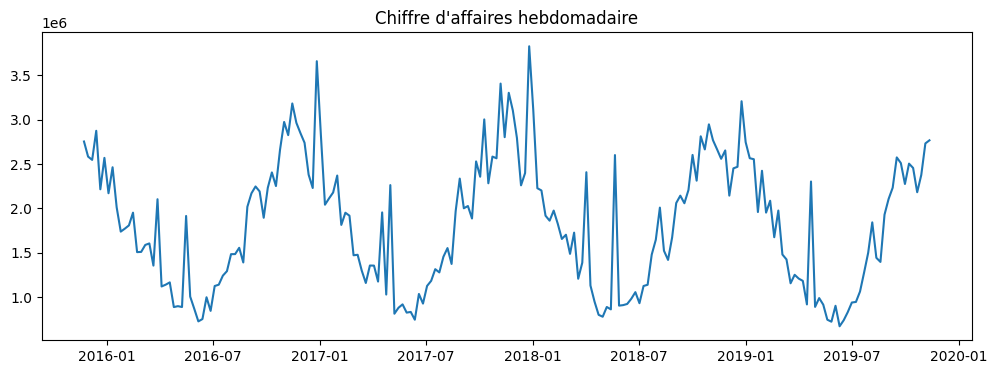

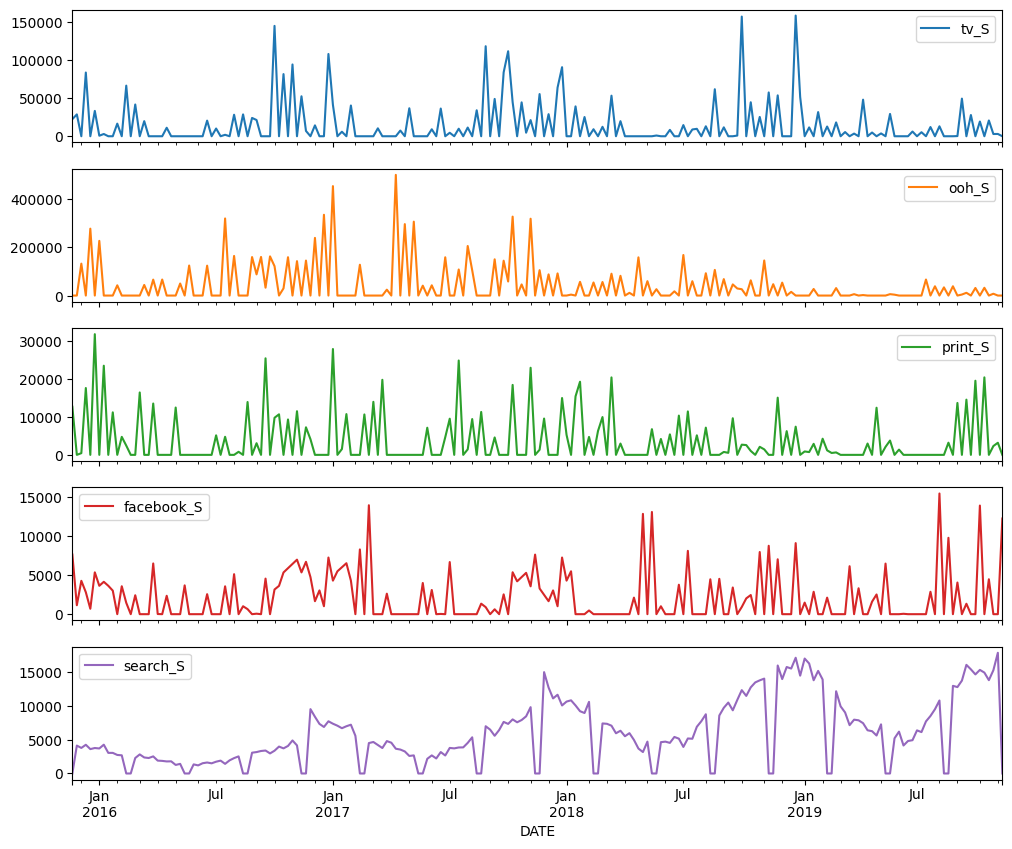

In [25]:
plt.figure(figsize=(12, 4))
plt.plot(df["DATE"], df["revenue"])
plt.title("Chiffre d'affaires hebdomadaire")
plt.show()

df.set_index("DATE")[canaux].plot(subplots=True, figsize=(12, 10))
plt.show()

## 2. Adstock

In [26]:
import numpy as np

def adstock(depenses, taux):
    resultat = []
    reste = 0
    for d in depenses:
        reste = d + taux * reste
        resultat.append(reste)
    return np.array(resultat)

In [27]:
df["tv_adstock"] = adstock(df["tv_S"], 0.5)

df[["DATE", "tv_S", "tv_adstock"]].iloc[10:20]

,DATE,tv_S,tv_adstock
10,2016-02-01,16511.826667,18691.762161
11,2016-02-08,0.000000,9345.881081
12,2016-02-15,66276.440000,70949.380540
13,2016-02-22,0.000000,35474.690270
14,2016-02-29,41556.293333,59293.638468
15,2016-03-07,0.000000,29646.819234
16,2016-03-14,19772.440000,34595.849617
17,2016-03-21,0.000000,17297.924809
18,2016-03-28,0.000000,8648.962404
19,2016-04-04,0.000000,4324.481202


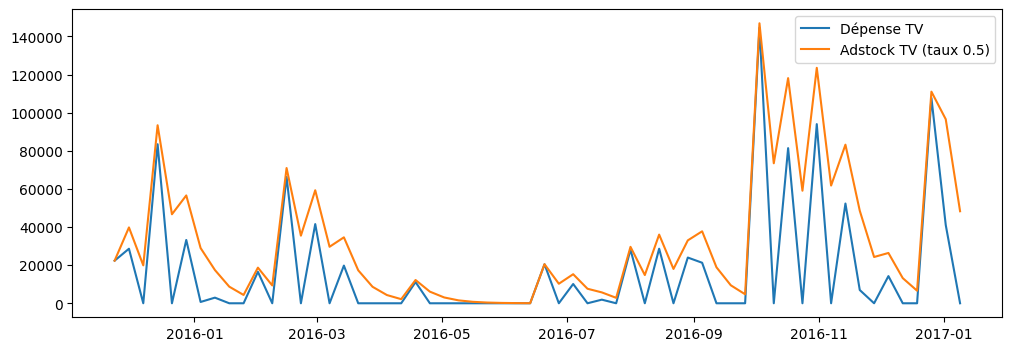

In [28]:
plt.figure(figsize=(12, 4))
plt.plot(df["DATE"][:60], df["tv_S"][:60], label="Dépense TV")
plt.plot(df["DATE"][:60], df["tv_adstock"][:60], label="Adstock TV (taux 0.5)")
plt.legend()
plt.show()

In [29]:
def saturation(x, demi, forme):
    return x**forme / (x**forme + demi**forme)

## 3. Saturation

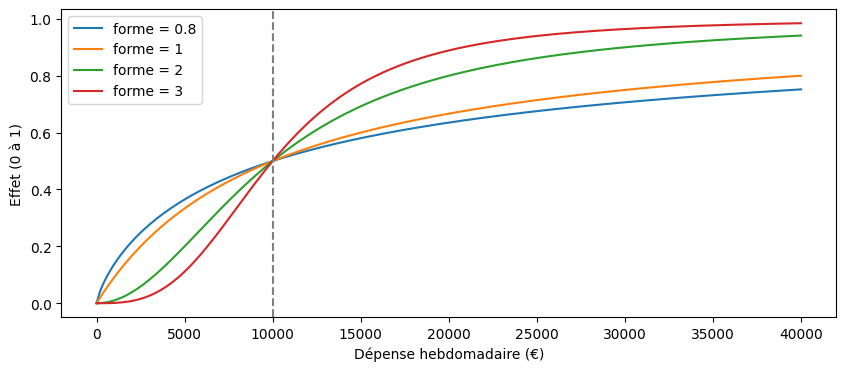

In [30]:
x = np.linspace(0, 40000, 200)

plt.figure(figsize=(10, 4))
for f in [0.8, 1, 2, 3]:
    plt.plot(x, saturation(x, 10000, f), label=f"forme = {f}")
plt.axvline(10000, color="grey", linestyle="--")
plt.xlabel("Dépense hebdomadaire (€)")
plt.ylabel("Effet (0 à 1)")
plt.legend()
plt.show()

## 4. Model

In [31]:
semaine = df["DATE"].dt.isocalendar().week.astype(int)

controles = pd.DataFrame({
    "saison_sin": np.sin(2 * np.pi * semaine / 52),
    "saison_cos": np.cos(2 * np.pi * semaine / 52),
    "tendance": np.arange(len(df)),
    "concurrents": df["competitor_sales_B"],
    "newsletter": df["newsletter"],
    "evenement": (df["events"] != "na").astype(int),
})
y = df["revenue"].values

In [32]:
def transformer(params):
    X = controles.copy()
    for i, c in enumerate(canaux):
        taux, demi, forme = params[3*i : 3*i + 3]
        a = adstock(df[c].values, taux)
        X[c] = saturation(a, demi * a.max(), forme)
    return X

In [33]:
from scipy.optimize import lsq_linear, differential_evolution

def ajuster(X):
    A = np.column_stack([np.ones(len(X)), X.values])
    bas = [-np.inf] + [-np.inf if c in controles.columns else 0 for c in X.columns]
    r = lsq_linear(A, y, bounds=(bas, [np.inf] * len(bas)))
    return r.x, A

def erreur(params):
    coefs, A = ajuster(transformer(params))
    return np.mean((y - A @ coefs) ** 2)

In [34]:
bornes = []
for c in canaux:
    if c in ["tv_S", "ooh_S", "print_S"]:
        bornes += [(0, 0.8), (0.1, 1), (0.5, 3)]
    else:
        bornes += [(0, 0.3), (0.1, 1), (0.5, 3)]

res = differential_evolution(erreur, bornes, seed=42, maxiter=100, polish=False)

params = pd.DataFrame(res.x.reshape(5, 3), index=canaux, columns=["taux", "demi", "forme"])
params.round(2)

,taux,demi,forme
tv_S,0.11,0.38,1.12
ooh_S,0.55,0.89,1.00
print_S,0.12,0.47,2.16
facebook_S,0.18,0.31,2.90
search_S,0.14,0.74,2.75


R² : 0.92


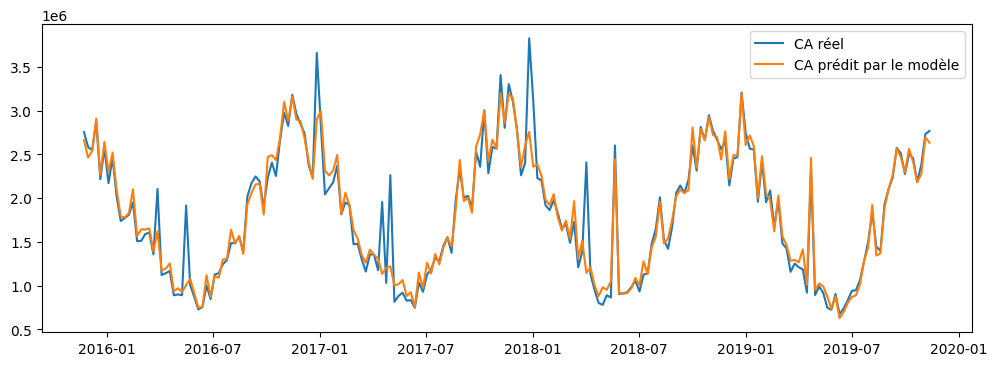

In [35]:
X = transformer(res.x)
coefs, A = ajuster(X)
prediction = A @ coefs

r2 = 1 - ((y - prediction) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print("R² :", round(r2, 3))

plt.figure(figsize=(12, 4))
plt.plot(df["DATE"], y, label="CA réel")
plt.plot(df["DATE"], prediction, label="CA prédit par le modèle")
plt.legend()
plt.show()

In [36]:
noms = list(X.columns)
contribution = {c: (coefs[1 + noms.index(c)] * X[c]).sum() for c in canaux}

resultats = pd.DataFrame({
    "depense_totale": df[canaux].sum(),
    "CA_genere": pd.Series(contribution),
})
resultats["ROI"] = resultats["CA_genere"] / resultats["depense_totale"]
resultats["part_budget_%"] = resultats["depense_totale"] / resultats["depense_totale"].sum() * 100
resultats.round(2).sort_values("ROI", ascending=False)

,depense_totale,CA_genere,ROI,part_budget_%
facebook_S,446296.83,7462990.73,16.72,3.07
search_S,1230426.67,8213699.09,6.68,8.47
tv_S,3087487.77,19459372.58,6.30,21.25
print_S,775555.51,4822203.64,6.22,5.34
ooh_S,8989331.73,11541961.61,1.28,61.87


## 5. Response curves and budget optimisation

In [37]:
courbe = {}
for c in canaux:
    taux, demi, forme = params.loc[c]
    a_max = adstock(df[c].values, taux).max()
    courbe[c] = {"taux": taux, "demi": demi * a_max, "forme": forme,
                 "poids": coefs[1 + noms.index(c)]}

def reponse(c, depense):
    p = courbe[c]
    return p["poids"] * saturation(depense / (1 - p["taux"]), p["demi"], p["forme"])

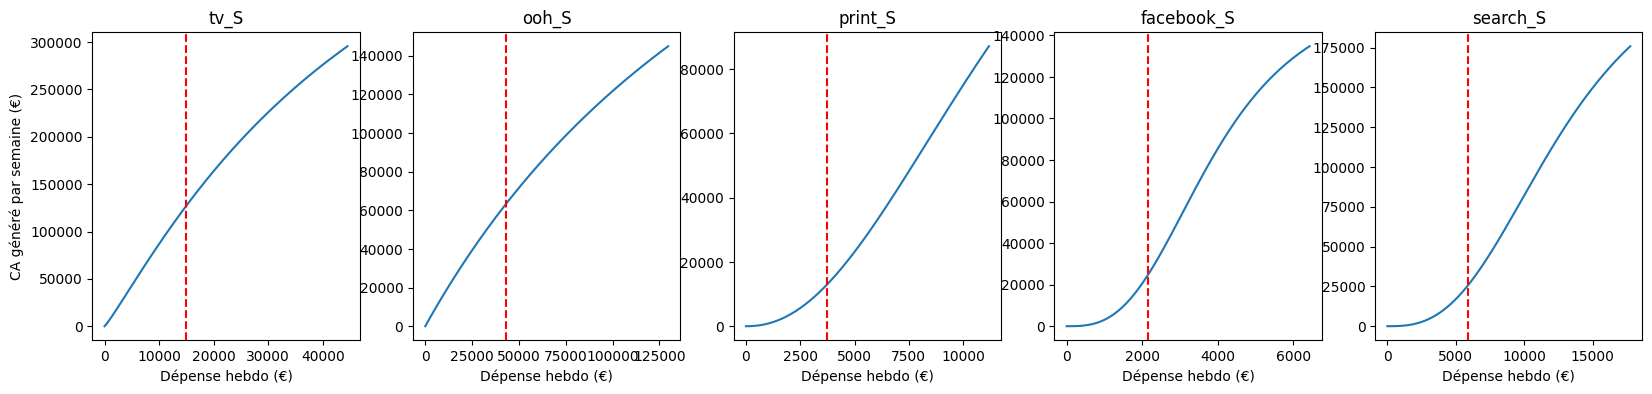

In [38]:
actuel = df[canaux].mean()

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, canaux):
    x = np.linspace(0, actuel[c] * 3, 200)
    ax.plot(x, reponse(c, x))
    ax.axvline(actuel[c], color="red", linestyle="--")
    ax.set_title(c)
    ax.set_xlabel("Dépense hebdo (€)")
axes[0].set_ylabel("CA généré par semaine (€)")
plt.show()

In [39]:
from scipy.optimize import minimize

budget = actuel.sum()

def ca_negatif(depenses):
    return -sum(reponse(c, d) for c, d in zip(canaux, depenses))

limites = [(0.5 * actuel[c], 1.5 * actuel[c]) for c in canaux]
contrainte = {"type": "eq", "fun": lambda d: d.sum() - budget}

opt = minimize(ca_negatif, actuel.values, bounds=limites,
               constraints=contrainte, method="SLSQP")

reco = pd.DataFrame({"actuel": actuel, "recommande": opt.x})
reco["part_actuelle_%"] = reco["actuel"] / budget * 100
reco["part_recommandee_%"] = reco["recommande"] / budget * 100
reco["variation_%"] = (reco["recommande"] / reco["actuel"] - 1) * 100
reco.round(1)

,actuel,recommande,part_actuelle_%,part_recommandee_%,variation_%
tv_S,14843.7,22265.5,21.3,31.9,50.0
ooh_S,43217.9,29901.2,61.9,42.8,-30.8
print_S,3728.6,5592.9,5.3,8.0,50.0
facebook_S,2145.7,3218.5,3.1,4.6,50.0
search_S,5915.5,8873.3,8.5,12.7,50.0


In [40]:
ca_avant = -ca_negatif(actuel.values)
ca_apres = -ca_negatif(opt.x)
gain = ca_apres - ca_avant

print(f"Gain hebdomadaire : {gain:,.0f} €")
print(f"Soit {gain / df['revenue'].mean() * 100:.1f} % du CA hebdomadaire total")

Gain hebdomadaire : 125,814 €
Soit 6.9 % du CA hebdomadaire total
